Imports and Settings

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.width", 200, "display.max_columns", 40)

DATA_PATH = "ecommerce_customer_churn_dataset.csv"   # <-- change if your file is elsewhere
RANDOM_STATE = 42
TARGET = "Churned"
CAT = ["Gender", "Country", "Signup_Quarter"]         # City is dropped (see 4.3)
os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)

Load Data and Make Split 80/20

In [2]:
df = pd.read_csv(DATA_PATH)
X, y = df.drop(columns=TARGET), df[TARGET]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Full data:", df.shape, "| train:", Xtr.shape, "| test:", Xte.shape)
print("Churn rate  full %.3f | train %.3f | test %.3f" % (y.mean(), ytr.mean(), yte.mean()))

Full data: (50000, 25) | train: (40000, 24) | test: (10000, 24)
Churn rate  full 0.289 | train 0.289 | test 0.289


The Preparation Pipeline

In [3]:
class Cleaner(BaseEstimator, TransformerMixin):
    """Rule-based correction of invalid values (4.1), dropping City (4.3), engineered features (4.5)."""
    def __init__(self, fe=True, drop_city=True, clean=True, logs=False):
        self.fe, self.drop_city, self.clean, self.logs = fe, drop_city, clean, logs
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        if self.clean:
            X.loc[(X.Age < 18) | (X.Age > 100), "Age"] = np.nan          # impossible ages -> missing
            X.loc[X.Total_Purchases < 0, "Total_Purchases"] = np.nan      # negative counts -> missing
            X["Total_Purchases"] = X.Total_Purchases.round()              # a count must be whole
            for c in ["Cart_Abandonment_Rate", "Discount_Usage_Rate"]:    # percentages capped at 100
                X[c] = X[c].clip(upper=100)
        if self.drop_city and "City" in X:
            X = X.drop(columns="City")
        if self.fe:                                                       # Table 4.2
            m = X.Membership_Years.clip(lower=0.1)
            X["Purchase_Frequency"]    = X.Total_Purchases / m
            X["Estimated_Spend"]       = X.Total_Purchases * X.Average_Order_Value
            X["Engagement_Index"]      = X.Login_Frequency * X.Session_Duration_Avg * X.Pages_Per_Session
            X["Service_Calls_per_Year"] = X.Customer_Service_Calls / m
            X["Recency_to_Tenure"]     = X.Days_Since_Last_Purchase / (m * 365)
        if self.logs:                                                     # only used in the rejected log-transform test
            cols = ["Average_Order_Value", "Total_Purchases", "Returns_Rate", "Days_Since_Last_Purchase",
                    "Lifetime_Value", "Membership_Years", "Wishlist_Items", "Product_Reviews_Written"]
            if self.fe:
                cols += ["Purchase_Frequency", "Estimated_Spend", "Engagement_Index", "Service_Calls_per_Year"]
            for c in cols:
                X[c] = np.log1p(X[c].clip(lower=0))
        return X

class Winsor(BaseEstimator, TransformerMixin):
    """Cap each numeric column at its 1st and 99th percentile (limits learned from training data)."""
    def __init__(self, lo=0.01, hi=0.99):
        self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.cols_ = list(X.columns); self.l_ = X.quantile(self.lo); self.h_ = X.quantile(self.hi)
        return self
    def get_feature_names_out(self, names=None):
        return np.array(self.cols_)
    def transform(self, X):
        return pd.DataFrame(X).clip(self.l_, self.h_, axis=1).values

def make_pre(fe=True, winsor=True, scale=True, clean=True, logs=False):
    num = Pipeline(([("w", Winsor())] if winsor else [])
                   + [("imp", SimpleImputer(strategy="median"))]
                   + ([("sc", StandardScaler())] if scale else []))
    ct = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), CAT),
         ("num", num, make_column_selector(dtype_include=np.number))],
        verbose_feature_names_out=False)
    ct.set_output(transform="pandas")
    return Pipeline([("clean", Cleaner(fe=fe, clean=clean, logs=logs)), ("ct", ct)])

def smote(X, y, k=5, seed=RANDOM_STATE):
    """Minimal SMOTE (Chawla et al., 2002). You may use imblearn.over_sampling.SMOTE instead."""
    rng = np.random.RandomState(seed); X = np.asarray(X); y = np.asarray(y)
    Xm = X[y == 1]; n_new = (y == 0).sum() - (y == 1).sum()
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Xm).kneighbors(Xm, return_distance=False)[:, 1:]
    i = rng.randint(0, len(Xm), n_new); j = idx[i, rng.randint(0, k, n_new)]; g = rng.rand(n_new, 1)
    return np.vstack([X, Xm[i] + g * (Xm[j] - Xm[i])]), np.r_[y, np.ones(n_new, int)]

Missing Value and Invalid Value 

In [6]:
miss = Xtr.isna().sum()
print("Columns with missing values (full data):", int((df.isna().sum() > 0).sum()), "of", df.shape[1])
print("TRAIN missing cells: %d (%.1f%% of all cells)" % (Xtr.isna().sum().sum(), 100 * Xtr.isna().sum().sum() / Xtr.size))
print("TRAIN rows with >=1 missing: %.1f%%" % (100 * Xtr.isna().any(axis=1).mean()))
miss_tab = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
miss_tab[miss_tab > 0].to_csv("tables/missing_by_column.csv", header=["missing_%"])
print(miss_tab[miss_tab > 0].to_string())

print("\nChurn rate when value is missing vs present (full data) – is missingness informative?")
for c in ["Social_Media_Engagement_Score", "Credit_Balance", "Mobile_App_Usage", "Returns_Rate"]:
    g = df.groupby(df[c].isna())[TARGET].mean().round(3)
    print(f"  {c:32s} present {g[False]:.3f} | missing {g[True]:.3f}")

print("\nInvalid values corrected by rules (full data)")
print("Age < 18          :", int((df.Age < 18).sum()), "| Age > 100:", int((df.Age > 100).sum()))
print("Total_Purchases<0 :", int((df.Total_Purchases < 0).sum()))
print("Cart_Abandonment > 100:", int((df.Cart_Abandonment_Rate > 100).sum()),
      "| Discount_Usage > 100:", int((df.Discount_Usage_Rate > 100).sum()))
print("Total_Purchases non-integer: %.1f%% of rows" % (100 * (df.Total_Purchases % 1 != 0).mean()))

Columns with missing values (full data): 14 of 25
TRAIN missing cells: 39156 (4.1% of all cells)
TRAIN rows with >=1 missing: 63.9%
Social_Media_Engagement_Score    12.0
Credit_Balance                   11.0
Mobile_App_Usage                 10.0
Returns_Rate                      9.0
Wishlist_Items                    8.0
Discount_Usage_Rate               7.0
Product_Reviews_Written           7.0
Session_Duration_Avg              6.8
Days_Since_Last_Purchase          6.0
Pages_Per_Session                 6.0
Email_Open_Rate                   5.1
Payment_Method_Diversity          5.0
Age                               5.0
Customer_Service_Calls            0.3

Churn rate when value is missing vs present (full data) – is missingness informative?
  Social_Media_Engagement_Score    present 0.288 | missing 0.297
  Credit_Balance                   present 0.288 | missing 0.295
  Mobile_App_Usage                 present 0.289 | missing 0.287
  Returns_Rate                     present 0.288 | mis

Duplication Detection

In [7]:
print("Exact duplicate rows in full data:", int(df.duplicated().sum()))
print("Exact duplicate rows in train:", int(Xtr.duplicated().sum()),
      "| rows of test that also appear in train:", int(Xte.merge(Xtr.drop_duplicates(), how="inner").shape[0]))

Exact duplicate rows in full data: 0
Exact duplicate rows in train: 0 | rows of test that also appear in train: 0


Encoding

In [8]:
cities_per_country = df.groupby("Country").City.nunique()
countries_per_city = df.groupby("City").Country.nunique()
print("Cities that belong to more than one country:", int((countries_per_city > 1).sum()), "of", len(countries_per_city))
print("Cities per country:", cities_per_country.to_dict())
churn_country = df.groupby("Country")[TARGET].mean().round(3)
print("Churn rate by country: min %.3f (%s) | max %.3f (%s)" %
      (churn_country.min(), churn_country.idxmin(), churn_country.max(), churn_country.idxmax()))
print("Gender counts:", df.Gender.value_counts().to_dict(), "| Signup_Quarter:", sorted(df.Signup_Quarter.unique()))
Xp = make_pre().fit_transform(Xtr, ytr)
dummies = [c for c in Xp.columns if c.startswith(("Gender_", "Country_", "Signup_Quarter_"))]
print("Dummy columns created:", len(dummies), dummies)
print("Final prepared matrix:", Xp.shape, "| missing cells left:", int(Xp.isna().sum().sum()))

Cities that belong to more than one country: 0 of 40
Cities per country: {'Australia': 5, 'Canada': 5, 'France': 5, 'Germany': 5, 'India': 5, 'Japan': 5, 'UK': 5, 'USA': 5}
Churn rate by country: min 0.273 (France) | max 0.299 (Australia)
Gender counts: {'Female': 25116, 'Male': 23947, 'Other': 937} | Signup_Quarter: ['Q1', 'Q2', 'Q3', 'Q4']
Dummy columns created: 12 ['Gender_Male', 'Gender_Other', 'Country_Canada', 'Country_France', 'Country_Germany', 'Country_India', 'Country_Japan', 'Country_UK', 'Country_USA', 'Signup_Quarter_Q2', 'Signup_Quarter_Q3', 'Signup_Quarter_Q4']
Final prepared matrix: (40000, 37) | missing cells left: 0


Winsorising and Scaling

In [9]:
cols = ["Average_Order_Value", "Returns_Rate", "Total_Purchases", "Days_Since_Last_Purchase",
        "Lifetime_Value", "Membership_Years"]
before = Xtr[cols]                                                    # raw training data
after = make_pre(scale=False).fit_transform(Xtr, ytr)[cols]            # cleaned + winsorised + imputed, not yet scaled
t41 = pd.DataFrame({"Skewness before": before.skew(), "Skewness after": after.skew(),
                    "Maximum before": before.max(), "Maximum after": after.max()}).round(2)
print(t41)
t41.to_csv("tables/table_4_1_skew.csv")
sc = make_pre().fit_transform(Xtr, ytr)
print("\nAfter StandardScaler (numeric columns): mean ~ %.3f, std ~ %.3f" %
      (sc.drop(columns=dummies).mean().mean(), sc.drop(columns=dummies).std().mean()))

                          Skewness before  Skewness after  Maximum before  Maximum after
Average_Order_Value                 40.72            0.73         9666.38         252.58
Returns_Rate                         5.94            1.16           99.62          22.00
Total_Purchases                      2.81            0.63          128.70          31.00
Days_Since_Last_Purchase             1.99            1.69          283.00         137.00
Lifetime_Value                       1.45            1.13         8987.24        4418.71
Membership_Years                     1.14            1.14           10.00          10.00

After StandardScaler (numeric columns): mean ~ -0.000, std ~ 1.000


Engineered Features

In [10]:
eng = Cleaner(clean=True, fe=True).transform(Xtr)[["Purchase_Frequency", "Estimated_Spend", "Engagement_Index",
                                                   "Service_Calls_per_Year", "Recency_to_Tenure"]]
print(eng.describe().T.round(2))
print("\nCorrelation of each engineered feature with churn (training set):")
print(eng.corrwith(ytr).round(3).to_string())


                          count     mean      std  min     25%      50%      75%        max
Purchase_Frequency      39968.0     9.13    22.07  0.0    2.63     4.76     9.09    1164.61
Estimated_Spend         39968.0  1626.63  3134.83  0.0  846.94  1335.92  2028.25  278296.03
Engagement_Index        35123.0  4538.76  5944.34  0.0  684.09  2318.56  6019.20   59852.80
Service_Calls_per_Year  39860.0     3.75     6.21  0.0    1.14     2.11     4.00     140.00
Recency_to_Tenure       37588.0     0.05     0.12  0.0    0.01     0.02     0.05       4.66

Correlation of each engineered feature with churn (training set):
Purchase_Frequency       -0.039
Estimated_Spend          -0.011
Engagement_Index         -0.154
Service_Calls_per_Year    0.076
Recency_to_Tenure         0.058


Feature Selection

In [11]:
Xp = make_pre().fit_transform(Xtr, ytr)
sel = SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=0.05), threshold=1e-6).fit(Xp, ytr)
print("Kept %d of %d features" % (sel.get_support().sum(), Xp.shape[1]))
print("Dropped:", list(Xp.columns[~sel.get_support()]))

Kept 29 of 37 features
Dropped: ['Gender_Other', 'Country_Canada', 'Country_Germany', 'Country_India', 'Country_Japan', 'Country_UK', 'Country_USA', 'Service_Calls_per_Year']


Principal Component Analysis

Components for 90% variance: 19 | for 95%: 23 | total features: 37
Correlation Session_Duration_Avg vs Pages_Per_Session: 0.76


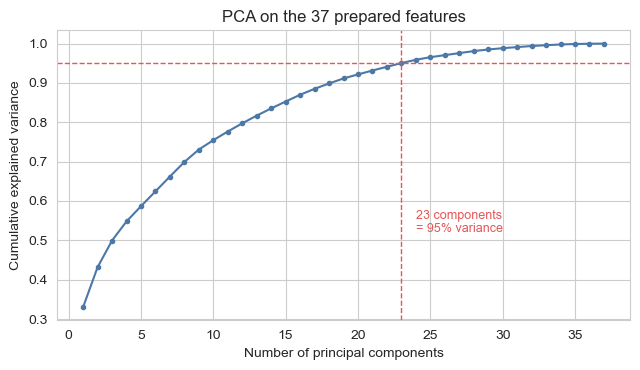

In [12]:
pca = PCA().fit(Xp)
cum = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1); n90 = int(np.searchsorted(cum, 0.90) + 1)
print(f"Components for 90% variance: {n90} | for 95%: {n95} | total features: {Xp.shape[1]}")
print("Correlation Session_Duration_Avg vs Pages_Per_Session: %.2f" %
      df[["Session_Duration_Avg", "Pages_Per_Session"]].corr().iloc[0, 1])
plt.figure(figsize=(6.5, 3.8))
plt.plot(range(1, len(cum) + 1), cum, marker="o", ms=3, c="#4c78a8")
plt.axhline(0.95, c="#e45756", ls="--", lw=1); plt.axvline(n95, c="#e45756", ls="--", lw=1)
plt.text(n95 + 1, 0.52, f"{n95} components\n= 95% variance", color="#e45756", fontsize=9)
plt.xlabel("Number of principal components"); plt.ylabel("Cumulative explained variance")
plt.title(f"PCA on the {Xp.shape[1]} prepared features"); plt.tight_layout()
plt.savefig("figures/fig_4_1_pca.png", dpi=150); plt.show()

Ablation Study, Class Weighting vs SMOTE

In [13]:
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

def run(name, kw, post=None, cw=None, use_smote=False):
    a, f, r, p = [], [], [], []
    for tr, va in skf.split(Xtr, ytr):
        pre = make_pre(**kw)
        A = pre.fit_transform(Xtr.iloc[tr], ytr.iloc[tr]); B = pre.transform(Xtr.iloc[va]); yt = ytr.iloc[tr].values
        if post == "pca":
            pc = PCA(0.95).fit(A); A, B = pc.transform(A), pc.transform(B)
        if post == "sel":
            s = SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=0.05), threshold=1e-6).fit(A, yt)
            A, B = s.transform(A), s.transform(B)
        if use_smote:
            A, yt = smote(A, yt)
        m = LogisticRegression(max_iter=2000, class_weight=cw).fit(A, yt)
        pr = m.predict_proba(B)[:, 1]; d = (pr > 0.5).astype(int); yv = ytr.iloc[va]
        a.append(roc_auc_score(yv, pr)); f.append(f1_score(yv, d))
        r.append(recall_score(yv, d)); p.append(precision_score(yv, d))
    res = dict(step=name, auc=float(np.mean(a)), auc_sd=float(np.std(a)), f1=float(np.mean(f)),
               recall=float(np.mean(r)), precision=float(np.mean(p)), n_features=int(A.shape[1]))
    print(res); return res

B = dict(fe=True, logs=False, winsor=True, clean=True)           # the adopted pipeline (step 4)
JOBS = [("1",  "1 Baseline (impute, scale, one-hot encode)", dict(fe=False, logs=False, winsor=False, clean=False), {}),
        ("2",  "2 + Correction of invalid values",           dict(fe=False, logs=False, winsor=False, clean=True),  {}),
        ("3",  "3 + Winsorising",                            dict(fe=False, logs=False, winsor=True,  clean=True),  {}),
        ("4b", "4 + Engineered features",                    B, {}),
        ("4a", "Log transform (on top of 4)",                dict(fe=True, logs=True, winsor=True, clean=True), {}),
        ("5a", "L1 feature selection (on top of 4)",         B, dict(post="sel")),
        ("5b", "PCA 95% (on top of 4)",                      B, dict(post="pca")),
        ("6a", "Class weighting (on top of 4)",             B, dict(cw="balanced")),
        ("6b", "SMOTE (on top of 4)",                        B, dict(use_smote=True))]
STEPS = os.environ.get("ABL", "1,2,3,4b,4a,5a,5b,6a,6b").split(",")   # leave as is to run everything
CACHE = "tables/ablation_results.json"
R = json.load(open(CACHE)) if os.path.exists(CACHE) else {}
for key, name, kw, extra in JOBS:
    if key in STEPS:
        R[key] = run(name, kw, **extra); json.dump(R, open(CACHE, "w"), indent=1)

{'step': '1 Baseline (impute, scale, one-hot encode)', 'auc': 0.7880409311900486, 'auc_sd': 0.007473546802164504, 'f1': 0.5237091851650227, 'recall': 0.42093425605536333, 'precision': 0.6932334811154921, 'n_features': 32}
{'step': '2 + Correction of invalid values', 'auc': 0.7882647375157559, 'auc_sd': 0.007481137693213094, 'f1': 0.5248835260828854, 'recall': 0.42249134948096884, 'precision': 0.6931452099318227, 'n_features': 32}
{'step': '3 + Winsorising', 'auc': 0.7902660977520818, 'auc_sd': 0.007578401858019215, 'f1': 0.5283350426200883, 'recall': 0.4278546712802768, 'precision': 0.690845328516376, 'n_features': 32}
{'step': '4 + Engineered features', 'auc': 0.7984374771874498, 'auc_sd': 0.007912937226028418, 'f1': 0.5535293560777899, 'recall': 0.4578719723183391, 'precision': 0.6999833998599538, 'n_features': 37}
{'step': 'Log transform (on top of 4)', 'auc': 0.7780282747872046, 'auc_sd': 0.008629876250433318, 'f1': 0.5093683794498636, 'recall': 0.4067474048442906, 'precision': 0.6

                                      Step  CV_AUC  CV_F1  CV_recall  CV_precision  AUC_sd
1 Baseline (impute, scale, one-hot encode)   0.788  0.524      0.421         0.693  0.0075
          2 + Correction of invalid values   0.788  0.525      0.422         0.693  0.0075
                           3 + Winsorising   0.790  0.528      0.428         0.691  0.0076
                   4 + Engineered features   0.798  0.554      0.458         0.700  0.0079
               Log transform (on top of 4)   0.778  0.509      0.407         0.682  0.0086
        L1 feature selection (on top of 4)   0.798  0.554      0.458         0.700  0.0078
                     PCA 95% (on top of 4)   0.784  0.518      0.417         0.685  0.0082
             Class weighting (on top of 4)   0.798  0.605      0.733         0.516  0.0076
                       SMOTE (on top of 4)   0.798  0.606      0.730         0.517  0.0076


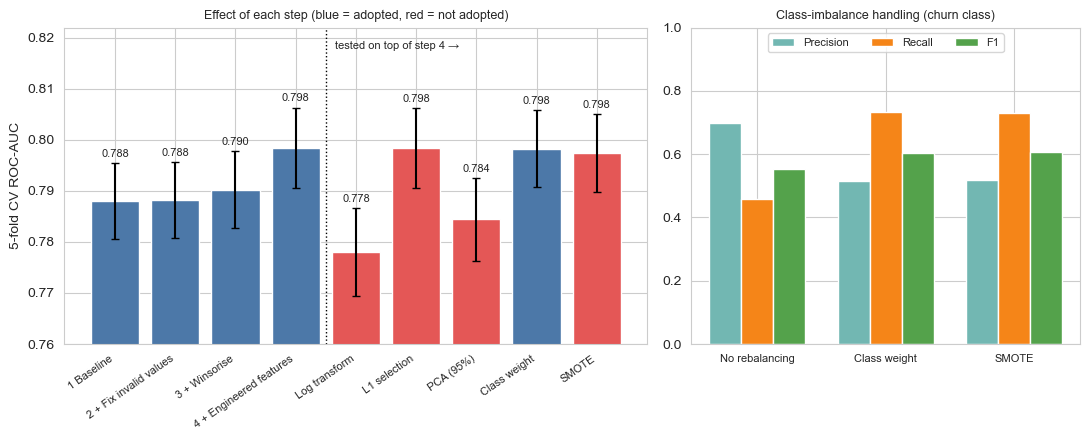

In [14]:
assert all(k in R for k, _, _, _ in JOBS), "Run Cell 10 (the ablation) first - some steps are missing."
rows = [dict(Step=name, CV_AUC=round(R[k]["auc"], 3), CV_F1=round(R[k]["f1"], 3),
             CV_recall=round(R[k]["recall"], 3), CV_precision=round(R[k]["precision"], 3),
             AUC_sd=round(R[k]["auc_sd"], 4)) for k, name, _, _ in JOBS if k in R]
t43 = pd.DataFrame(rows); print(t43.to_string(index=False)); t43.to_csv("tables/table_4_3_ablation.csv", index=False)

order = [("1", "1 Baseline"), ("2", "2 + Fix invalid values"), ("3", "3 + Winsorise"), ("4b", "4 + Engineered features"),
         ("4a", "Log transform"), ("5a", "L1 selection"), ("5b", "PCA (95%)"), ("6a", "Class weight"), ("6b", "SMOTE")]
rejected = {"4a", "5a", "5b", "6b"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
vals = [R[k]["auc"] for k, _ in order]; sds = [R[k]["auc_sd"] for k, _ in order]
ax[0].bar(range(9), vals, color=["#e45756" if k in rejected else "#4c78a8" for k, _ in order], yerr=sds, capsize=3)
ax[0].axvline(3.5, c="k", ls=":", lw=1); ax[0].text(3.65, 0.8195, "tested on top of step 4 →", fontsize=8, va="top")
ax[0].set_ylim(0.76, 0.822); ax[0].set_xticks(range(9))
ax[0].set_xticklabels([l for _, l in order], rotation=35, ha="right", fontsize=8)
for i, (v, s) in enumerate(zip(vals, sds)):
    ax[0].text(i, v + s + 0.0012, f"{v:.3f}", ha="center", fontsize=8)
ax[0].set_ylabel("5-fold CV ROC-AUC"); ax[0].set_title("Effect of each step (blue = adopted, red = not adopted)", fontsize=9)
w, x = 0.25, np.arange(3)
for j, (mt, c, l) in enumerate([("precision", "#72b7b2", "Precision"), ("recall", "#f58518", "Recall"), ("f1", "#54a24b", "F1")]):
    ax[1].bar(x + (j - 1) * w, [R[k][mt] for k in ["4b", "6a", "6b"]], w, label=l, color=c)
ax[1].set_xticks(x); ax[1].set_xticklabels(["No rebalancing", "Class weight", "SMOTE"], fontsize=8)
ax[1].set_ylim(0, 1.0); ax[1].legend(fontsize=8, ncol=3, loc="upper center")
ax[1].set_title("Class-imbalance handling (churn class)", fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig_4_2_ablation.png", dpi=150); plt.show()